# Integration with SymPy and SciPy

The **definite integral** of $f$ over $[a, b]$ is the signed area under the graph:
$$ \int_a^b f(x)\,dx = F(b) - F(a), \qquad \text{where } F'(x) = f(x). $$

There are two ways to compute it:

- **Exact (symbolic):** find an antiderivative $F$ with SymPy. Gives a formula, but not every function has one.
- **Numerical:** add up values of $f$ at sample points with SciPy. Always gives a number, but only approximately.

In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate

from IPython.display import display

x = sp.symbols("x")

## Part A. Exact integration with SymPy

### Step 1: indefinite integral

`sp.integrate(f, x)` returns **one** antiderivative. SymPy does **not** add the constant $+C$.

In [2]:
f = x**2 * sp.cos(x)
F = sp.integrate(f, x)
F

x**2*sin(x) + 2*x*cos(x) - 2*sin(x)

**Always check:** the derivative of $F$ must give back $f$.

In [3]:
sp.simplify(F.diff(x) - f)

0

### Step 2: definite integral

Pass a tuple `(x, a, b)` for the variable and the limits. Use exact numbers (`sp.pi`, `sp.Rational(1, 2)`), not floats.

In [4]:
I = sp.integrate(f, (x, 0, sp.pi))
display(I)
print("decimal:", I.evalf())

-2*pi

decimal: -6.28318530717959


### Step 3: improper integrals

An infinite limit is written with `sp.oo`.

In [5]:
display(sp.integrate(sp.exp(-x**2), (x, -sp.oo, sp.oo)))
display(sp.integrate(sp.sin(x)/x, (x, 0, sp.oo)))

sqrt(pi)

pi/2

### Step 4: when there is no elementary formula

Some antiderivatives exist only as **special functions**. For example $\int e^{-x^2}\,dx$ uses the error function $\operatorname{erf}$:

In [6]:
intval = sp.integrate(sp.exp(-x**2), x)
display(intval)

sqrt(pi)*erf(x)/2

For others SymPy finds nothing and returns the integral **unevaluated**. We can still ask for a number with `.evalf()`.

In [7]:
J = sp.integrate(sp.exp(sp.sin(x)), (x, 0, 1))
display(J)
print("decimal:", J.evalf())

Integral(exp(sin(x)), (x, 0, 1))

decimal: 1.63186960841805


## Part B. Numerical integration with SciPy

Split $[a, b]$ into $n$ equal pieces of width $h = (b - a)/n$, with points $x_0, x_1, \dots, x_n$. Each rule replaces $f$ by something simple on each piece.

Test problem with a known answer:
$$ \int_0^\pi \sin x \, dx = 2. $$

### Step 1: trapezoidal rule

Join the points by **straight lines**:
$$ \int_a^b f\,dx \approx \frac{h}{2}\Big(f_0 + 2f_1 + 2f_2 + \dots + 2f_{n-1} + f_n\Big). $$

`integrate.trapezoid(yv, x=xv)` takes the **sampled values**, not the function.

In [8]:
xv = np.linspace(0, np.pi, 11)     # 11 points, n = 10 pieces
yv = np.sin(xv)

T = integrate.trapezoid(yv, x=xv)
print("trapezoid:", T, "  error:", abs(T - 2))

trapezoid: 1.9835235375094544   error: 0.016476462490545574


### Step 2: Simpson's rule

Join the points in pairs of pieces by **parabolas** ($n$ even):
$$ \int_a^b f\,dx \approx \frac{h}{3}\Big(f_0 + 4f_1 + 2f_2 + 4f_3 + \dots + 4f_{n-1} + f_n\Big). $$

Same data, much smaller error:

In [9]:
S = integrate.simpson(yv, x=xv)
print("simpson:  ", S, "  error:", abs(S - 2))

simpson:   2.0001095173150043   error: 0.00010951731500430384


**Names.** Older notes use `integrate.trapz` and `integrate.simps`. These were **removed** in SciPy 1.14; use `trapezoid` and `simpson`.

### Step 3: how fast does the error shrink?

Halve $h$ and watch the error:
- trapezoid: error $\sim h^2$, so it drops by about $4$;
- Simpson: error $\sim h^4$, so it drops by about $16$.

On a log-log plot these are straight lines of slope $2$ and $4$.

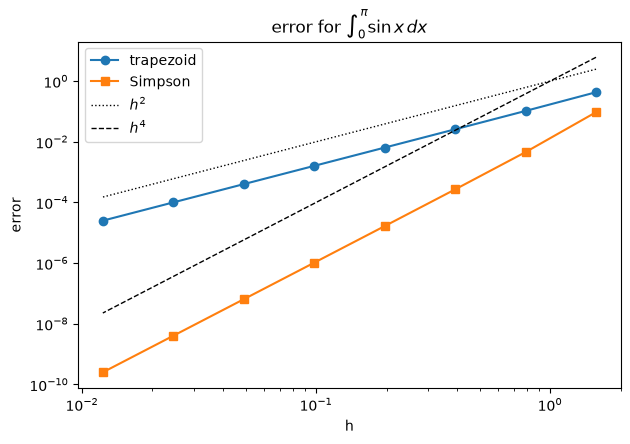

In [10]:
ns = 2**np.arange(1, 9)            # n = 2, 4, ..., 256 pieces
err_T, err_S = [], []
for n in ns:
    xv = np.linspace(0, np.pi, n + 1)
    err_T.append(abs(integrate.trapezoid(np.sin(xv), x=xv) - 2))
    err_S.append(abs(integrate.simpson(np.sin(xv), x=xv) - 2))

h = np.pi / ns
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(h, err_T, "o-", label="trapezoid")
ax.loglog(h, err_S, "s-", label="Simpson")
ax.loglog(h, h**2, "k:", lw=1, label=r"$h^2$")
ax.loglog(h, h**4, "k--", lw=1, label=r"$h^4$")
ax.set_xlabel("h"); ax.set_ylabel("error"); ax.legend()
ax.set_title(r"error for $\int_0^\pi \sin x\,dx$")
plt.show()

### Step 4: Gaussian quadrature

Trapezoid and Simpson use **equally spaced** points. Gauss-Legendre quadrature chooses the points $x_i$ and weights $w_i$ in the best possible way:
$$ \int_a^b f\,dx \approx \sum_{i=1}^{n} w_i\, f(x_i). $$

With $n$ points it is **exact for every polynomial of degree $\le 2n - 1$**.

`integrate.fixed_quad(f, a, b, n=n)` takes the **function** (not samples) and returns `(value, None)`.

In [11]:
print(" points   Gauss error   Simpson error")
for n in [3, 5, 7, 9]:
    G, _ = integrate.fixed_quad(np.sin, 0, np.pi, n=n)
    xv = np.linspace(0, np.pi, n)
    S = integrate.simpson(np.sin(xv), x=xv)
    print(f"{n:6d}   {abs(G - 2):.1e}       {abs(S - 2):.1e}")

 points   Gauss error   Simpson error
     3   1.4e-03       9.4e-02
     5   1.1e-07       4.6e-03
     7   1.8e-12       8.6e-04
     9   1.3e-15       2.7e-04


With the **same number of points**, Gauss wins by orders of magnitude. Its nodes are not equally spaced and its weights are not equal. On $[-1, 1]$ with $n = 3$:

In [12]:
nodes, weights = np.polynomial.legendre.leggauss(3)
print("nodes:  ", nodes)
print("weights:", weights)

nodes:   [-0.77459667  0.          0.77459667]
weights: [0.55555556 0.88888889 0.55555556]


### Step 5: `quad`, the everyday tool

`integrate.quad(f, a, b)` uses adaptive Gaussian quadrature: it adds points where $f$ is hard until the answer is accurate. It returns `(value, error estimate)` and accepts infinite limits `np.inf`.

In [13]:
val, err = integrate.quad(np.sin, 0, np.pi)
print("quad:", val, "  estimated error:", err)

val, err = integrate.quad(lambda s: np.exp(-s**2), -np.inf, np.inf)
print("quad:", val, "  exact sqrt(pi):", np.sqrt(np.pi))

quad: 2.0   estimated error: 2.220446049250313e-14
quad: 1.7724538509055159   exact sqrt(pi): 1.7724538509055159


It also handles the integral SymPy could not do in Part A:

In [14]:
val, err = integrate.quad(lambda s: np.exp(np.sin(s)), 0, 1)
print("quad: ", val)
print("SymPy:", J.evalf())

quad:  1.6318696084180513
SymPy: 1.63186960841805


## Summary

| | SymPy (exact) | SciPy (numerical) |
|---|---|---|
| input | a formula | sampled values, or a Python function |
| call | `sp.integrate(f, (x, a, b))` | `trapezoid`, `simpson`, `fixed_quad`, `quad` |
| result | exact number or formula | float, approximate |
| can fail? | yes: returns `Integral(...)` | no, but check the error |

| rule | uses | error |
|---|---|---|
| trapezoid | straight lines, equal spacing | $\sim h^2$ |
| Simpson | parabolas, equal spacing | $\sim h^4$ |
| Gauss-Legendre, $n$ points | best points and weights | exact for degree $\le 2n - 1$ |

- **Always check** a symbolic antiderivative by differentiating it.
- **Use exact numbers** in SymPy (`sp.pi`, `sp.Rational`).
- **Compare** numerical answers with an exact one whenever you have it.

## Exercises

**Syntax**

| task | call |
|---|---|
| exact, 1d | `sp.integrate(f, (x, a, b))`, then `.evalf()` for a decimal |
| samples | `xv = np.linspace(a, b, n + 1)`, `yv = f(xv)` |
| trapezoid, Simpson | `integrate.trapezoid(yv, x=xv)`, `integrate.simpson(yv, x=xv)` |
| Gauss | `integrate.fixed_quad(f, a, b, n=3)[0]`, `integrate.quad(f, a, b)[0]` |

**Exercise 1.** Compute
$$ \int_0^1 x^2 e^{x} \, dx. $$

(a) **SymPy.** Compute the exact value of the integral and its decimal.

(b) **SciPy.** Using $11$ equally spaced points, compute the integral with `trapezoid` and `simpson`. Which one is closer to the exact value from (a)?

In [15]:
# Exercise 1


**Exercise 2.** Compute
$$ \int_0^2 e^{-x^2} \, dx. $$

(a) **SymPy.** Compute the integral. Which special function appears in the answer? Find its decimal value.

(b) **SciPy.** Compute the integral with `fixed_quad` using $n = 4$ points, and with `quad`. Compare both with the value from (a).

In [16]:
# Exercise 2
